En los ítems $4.1$ a $4.3$ usamos los experimentos tamanos y desorden, y cada lista medida es una observación de la regresión. Para el ítem $4.4$ debera generar un nuevo set de listas de simulación variando el valor de $k$

In [16]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Variables globales
rng = np.random.default_rng(4)

## Ejercicio 4.1

Complejidad de insertion sort. Con las mediciones para $n = 10, 20, 50, 100, 200, 500, 1000$, grafique $S_n$ en función de $n$ y muestre que la dependencia no es lineal.

observaciones por n: [200, 200, 200, 200, 200, 200, 200]


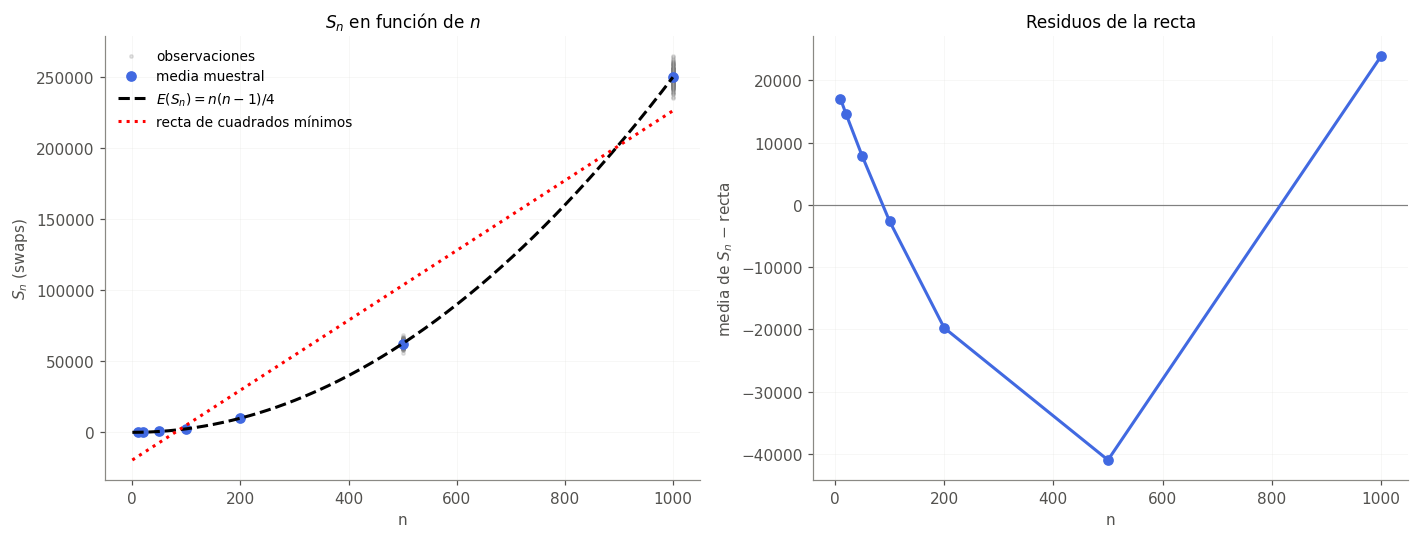

,media de S_n,media de S_n / n,(n − 1) / 4
n,,,
10,21.70,2.17,2.25
20,95.27,4.76,4.75
50,613.25,12.26,12.25
100,2466.42,24.66,24.75
200,9908.94,49.54,49.75
500,62365.36,124.73,124.75
1000,249982.92,249.98,249.75


In [17]:
ns = [10, 20, 50, 100, 200, 500, 1000]
sn_tamanos = {m: [] for m in ns}        # S_n 
qn_tamanos = {m: [] for m in ns}        # Q_n 

conteosJSON = open("conteos.jsonl", "r")

for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "tamanos":
        if datos["algoritmo"] == "insertion":
            sn_tamanos[datos["n"]].append(datos["swaps"])
        elif datos["algoritmo"] == "quick_primero":
            qn_tamanos[datos["n"]].append(datos["comparaciones"])

conteosJSON.close()

print("observaciones por n:", [len(sn_tamanos[m]) for m in ns])

# S_n en función de n
sn_medias = np.array([np.mean(sn_tamanos[m]) for m in ns])
x_obs = np.concatenate([np.full(len(sn_tamanos[m]), m) for m in ns])
y_obs = np.concatenate([sn_tamanos[m] for m in ns])

b, a = np.polyfit(x_obs, y_obs, 1)                  # recta S = a + b n sobre todas las observaciones
residuos_recta = sn_medias - (a + b * np.array(ns))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(x_obs, y_obs, s=5, alpha=0.2, color="gray", label="observaciones")
ax1.plot(ns, sn_medias, "o", color="royalblue", label="media muestral")
grilla = np.linspace(0, 1000, 300)
ax1.plot(grilla, grilla * (grilla - 1) / 4, "k--", label=r"$E(S_n)=n(n-1)/4$")
ax1.plot(grilla, a + b * grilla, "r:", lw=2, label="recta de cuadrados mínimos")
ax1.set_xlabel("n"); ax1.set_ylabel(r"$S_n$ (swaps)")
ax1.set_title(r"$S_n$ en función de $n$")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.axhline(0, color="gray", lw=0.8)
ax2.plot(ns, residuos_recta, "o-", color="royalblue")
ax2.set_xlabel("n"); ax2.set_ylabel(r"media de $S_n$ − recta")
ax2.set_title("Residuos de la recta")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Si la dependencia fuera lineal, S_n / n sería constante
pd.DataFrame({"media de S_n": sn_medias,
              "media de S_n / n": sn_medias / np.array(ns),
              "(n − 1) / 4": (np.array(ns) - 1) / 4},
             index=pd.Index(ns, name="n")).round(2)


La dependencia de $S_n$ con $n$ no es lineal. Si lo fuera, el cociente $S_n/n$ sería constante, pero crece con $n$: pasa de $2{,}17$ con $n = 10$ a $24{,}66$ con $n = 100$ y a $249{,}98$ con $n = 1000$, siguiendo $(n-1)/4$, que es $\mathrm{E}(S_n)/n$.

En el gráfico las medias muestrales caen sobre la curva $\mathrm{E}(S_n) = n(n-1)/4$ y se apartan de la recta de cuadrados mínimos. Los residuos de la recta (media de $S_n$ menos recta) tienen forma de U, que es el patrón típico de ajustar una recta a una curva convexa. Son positivos para $n$ chico (la recta predice unos $-17\,000$ swaps, que es un valor imposible), negativos en el medio (llegan a unos $-40\,000$ con $n = 500$) y positivos otra vez con $n = 1000$. Es el crecimiento cuadrático: al multiplicar $n$ por 10, $S_n$ se multiplica por casi 100 y no por 10.

### a)

A partir de la fórmula de $E(S_n)$, ¿qué valores de $\beta_0$ y $\beta_1$ espera para $n$ grande en la regresión ln $S_n = \beta_0 + \beta_1 ln( n )+ \epsilon$? Ajústela y construya intervalos de confianza de nivel $0,95$ para $\beta_0$ y $\beta_1$. Contraste $H_0 : \beta_1 = 2$ usando todos los $n$ ($1400$ observaciones) y usando solo $n \geq 100$ ($800$ observaciones).

---

Como $\mathrm{E}(S_n) = \dfrac{n(n-1)}{4} = \dfrac{n^2}{4}\left(1 - \dfrac{1}{n}\right)$, tomando logaritmos
$$\ln \mathrm{E}(S_n) = 2\ln n - \ln 4 + \ln\left(1 - \tfrac{1}{n}\right).$$
Para $n$ grande el último término tiende a $0$, así que esperamos $\beta_1 = 2$ y $\beta_0 = -\ln 4 \approx -1{,}386$.

Ajustamos por cuadrados mínimos usando las observaciones individuales (cada lista es una observación). Los intervalos son $\hat\beta_j \pm t_{N-2,\,0{,}975}\,\widehat{\mathrm{EE}}(\hat\beta_j)$, y el estadístico del test es $T = (\hat\beta_1 - 2)/\widehat{\mathrm{EE}}(\hat\beta_1)$ con distribución $t_{N-2}$ bajo $H_0$. La función `ols` también calcula errores estándar robustos (HC3), que se usan en los ítems siguientes.

In [18]:

#  regresión ln S_n = b0 + b1 ln n (4.1a)
def ols(x, y):
    """Cuadrados mínimos para y = b0 + b1 x. Errores clásicos y HC3 (robustos a varianza no constante)."""
    X = np.column_stack([np.ones_like(x), x])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    gl = len(y) - 2
    se = np.sqrt(np.diag(e @ e / gl * XtX_inv))
    h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
    meat = X.T @ (X * (e**2 / (1 - h)**2)[:, None])
    se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    return {"beta": beta, "se": se, "se_hc3": se_hc3, "resid": e, "gl": gl}

def datos_loglog(ms):
    x = np.concatenate([np.full(len(sn_tamanos[m]), np.log(m)) for m in ms])
    y = np.log(np.concatenate([sn_tamanos[m] for m in ms]))
    return x, y

ns_100 = [m for m in ns if m >= 100]
r_todos = ols(*datos_loglog(ns))
r_100 = ols(*datos_loglog(ns_100))

def fila_regresion(r, nombre):
    t975 = stats.t.ppf(0.975, r["gl"])
    (b0, b1), (se0, se1) = r["beta"], r["se"]
    t1 = (b1 - 2) / se1                                  # H0: β1 = 2
    p1 = 2 * stats.t.sf(abs(t1), r["gl"])
    return {"Ajuste": nombre, "N": r["gl"] + 2,
            "β̂0": b0, "IC 95 % β0": f"[{b0 - t975*se0:.3f}, {b0 + t975*se0:.3f}]",
            "β̂1": b1, "IC 95 % β1": f"[{b1 - t975*se1:.4f}, {b1 + t975*se1:.4f}]",
            "t (H0: β1 = 2)": round(t1, 2), "p-valor": f"{p1:.2e}"}

print(f"Valores esperados para n grande: β0 = −ln 4 = {-np.log(4):.4f}, β1 = 2")
tabla_41a = pd.DataFrame([fila_regresion(r_todos, "todos los n"),
                          fila_regresion(r_100, "n ≥ 100")]).set_index("Ajuste")
tabla_41a

Valores esperados para n grande: β0 = −ln 4 = -1.3863, β1 = 2


,N,β̂0,IC 95 % β0,β̂1,IC 95 % β1,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,
todos los n,1400,-1.568721,"[-1.591, -1.546]",2.030569,"[2.0259, 2.0352]",12.87,6.89e-36
n ≥ 100,800,-1.433742,"[-1.455, -1.413]",2.006981,"[2.0034, 2.0106]",3.78,1.66e-04


Con todos los $n$: $\hat\beta_1 = 2{,}031$ con intervalo $[2{,}026;\ 2{,}035]$, y $\hat\beta_0 = -1{,}569$ con intervalo $[-1{,}591;\ -1{,}546]$. El test de $H_0: \beta_1 = 2$ da $T = 12{,}87$ y $p = 6{,}9\cdot 10^{-36}$: **se rechaza**.

Con $n \geq 100$: $\hat\beta_1 = 2{,}007$ con intervalo $[2{,}003;\ 2{,}011]$, y $\hat\beta_0 = -1{,}434$ con intervalo $[-1{,}455;\ -1{,}413]$. El test da $T = 3{,}78$ y $p = 1{,}7\cdot 10^{-4}$: también **se rechaza**.

Ningún intervalo contiene los valores esperados ($2$ y $-1{,}386$), aunque con $n \geq 100$ los estimadores quedan mucho más cerca. En el ítem b) vemos por qué.

### b)

Compare las estimaciones de los dos ajustes y explique la diferencia a partir de la fórmula exacta de E(S_n). Si con $n \geq 100$ el test también rechaza, ¿eso contradice que el exponente asintótico es $2$? ¿Qué tan grande es la diferencia entre $\hat{\beta_1}$ y $2$?


----
Primero comparamos, para cada $n$, la recta asintótica $2\ln n - \ln 4$ con el valor exacto de $\mathrm{E}[\ln S_n]$. Para esto usamos la aproximación de segundo orden $\mathrm{E}[\ln S_n] \approx \ln \mathrm{E}(S_n) - \dfrac{\mathrm{Var}(S_n)}{2\,\mathrm{E}(S_n)^2}$. También incluimos la pendiente local de $\ln \mathrm{E}(S_n)$ respecto de $\ln n$.

In [25]:
def e_ln_S(m):
    """E[ln S_n] ≈ ln E(S_n) − Var(S_n) / (2 E(S_n)²)  (aproximación de segundo orden)."""
    mu = m * (m - 1) / 4
    var = m * (m - 1) * (2 * m + 5) / 72
    return np.log(mu) - var / (2 * mu**2)

ns_arr = np.array(ns)
display(pd.DataFrame({
    "2 ln n − ln 4": 2 * np.log(ns_arr) - np.log(4),
    "ln(1 − 1/n)": np.log(1 - 1 / ns_arr),
    "E[ln S_n] (teórico)": [e_ln_S(m) for m in ns],
    "media muestral de ln S_n": [np.mean(np.log(sn_tamanos[m])) for m in ns],
    "pendiente local 2 + 1/(n−1)": 2 + 1 / (ns_arr - 1),
}, index=pd.Index(ns, name="n")).round(4))

,2 ln n − ln 4,ln(1 − 1/n),E[ln S_n] (teórico),media muestral de ln S_n,pendiente local 2 + 1/(n−1)
n,,,,,
10,3.2189,-0.1054,3.0827,3.0412,2.1111
20,4.6052,-0.0513,4.5407,4.5441,2.0526
50,6.4378,-0.0202,6.4128,6.4140,2.0204
100,7.8240,-0.0101,7.8117,7.8082,2.0101
200,9.2103,-0.0050,9.2042,9.2001,2.0050
500,11.0429,-0.0020,11.0405,11.0403,2.0020
1000,12.4292,-0.0010,12.4280,12.4289,2.0010


Después calculamos qué pendiente e intercepto daría la regresión si los datos coincidieran exactamente con $\mathrm{E}[\ln S_n]$ (con las mismas 200 observaciones por $n$), y lo comparamos con lo estimado.

In [20]:
def pendiente_teorica(ms):
    """Recta de cuadrados mínimos de E[ln S_n] sobre ln n, con el mismo diseño de muestreo."""
    x, _ = datos_loglog(ms)
    y = np.concatenate([np.full(len(sn_tamanos[m]), e_ln_S(m)) for m in ms])
    b1, b0 = np.polyfit(x, y, 1)
    return b0, b1

b0_t, b1_t = pendiente_teorica(ns)
b0_t100, b1_t100 = pendiente_teorica(ns_100)

pd.DataFrame({
    "β̂1 (muestra)": [r_todos["beta"][1], r_100["beta"][1]],
    "β1 teórico": [b1_t, b1_t100],
    "EE (HC3) de β̂1": [r_todos["se_hc3"][1], r_100["se_hc3"][1]],
    "β̂0 (muestra)": [r_todos["beta"][0], r_100["beta"][0]],
    "β0 teórico": [b0_t, b0_t100],
}, index=["todos los n", "n ≥ 100"]).round(4)

for nombre, r in [("todos los n", r_todos), ("n ≥ 100", r_100)]:
    b1 = r["beta"][1]
    print(f"{nombre:11s}: β̂1 − 2 = {b1 - 2:.4f}  ({100 * (b1 - 2) / 2:.2f} % de 2).  "
          f"Efecto sobre S_1000 / S_100: 10^β̂1 = {10**b1:.1f} en vez de 100")

todos los n: β̂1 − 2 = 0.0306  (1.53 % de 2).  Efecto sobre S_1000 / S_100: 10^β̂1 = 107.3 en vez de 100
n ≥ 100    : β̂1 − 2 = 0.0070  (0.35 % de 2).  Efecto sobre S_1000 / S_100: 10^β̂1 = 101.6 en vez de 100


**Por qué cambian las estimaciones.** El término $\ln(1 - 1/n)$ de la fórmula exacta no es despreciable para $n$ chico: vale $-0{,}105$ con $n = 10$ y $-0{,}001$ con $n = 1000$. Como depende de $n$, curva la relación entre $\ln \mathrm{E}(S_n)$ y $\ln n$: la pendiente local es
$$\frac{d \ln \mathrm{E}(S_n)}{d \ln n} = 2 + \frac{1}{n-1},$$
que vale $2{,}111$ con $n = 10$, $2{,}010$ con $n = 100$ y $2{,}001$ con $n = 1000$. La corrección de segundo orden de $\mathrm{E}[\ln S_n]$, que es aproximadamente $-2/(9n)$, empuja en el mismo sentido. Una recta ajustada sobre todos los $n$ promedia esas pendientes locales, y los $n$ chicos la hacen subir: $\hat\beta_1 = 2{,}031$. Al quedarnos con $n \geq 100$ la curvatura casi desaparece y $\hat\beta_1 = 2{,}007$. El intercepto se mueve en sentido contrario porque la recta pasa por el punto $(\overline{\ln n}, \overline{\ln S})$: si la pendiente sube, el intercepto baja ($-1{,}569$ contra $-1{,}434$, con $-\ln 4 = -1{,}386$ como límite).

Las estimaciones coinciden con lo que predice la fórmula exacta: la pendiente teórica es $2{,}0253$ con todos los $n$ y $2{,}0047$ con $n \geq 100$, y las estimadas ($2{,}0306$ y $2{,}0070$) están a $1{,}7$ y $1{,}1$ errores estándar (HC3) de ellas. Es decir que los datos son compatibles con $\mathrm{E}(S_n) = n(n-1)/4$ y la diferencia con $2$ no es un problema del modelo sino de usar $n$ finito.

**El rechazo con $n \geq 100$ no contradice el exponente asintótico.** El exponente $2$ es el límite cuando $n \to \infty$, mientras que $H_0: \beta_1 = 2$ habla de la pendiente de la recta ajustada en el rango $100 \leq n \leq 1000$, que vale $2{,}0047$ y no $2$. Con $800$ observaciones el error estándar es de $\approx 0{,}002$, así que el test detecta esa diferencia de $0{,}005$. Rechazar dice que en ese rango la pendiente no es exactamente $2$ y no que el exponente asintótico sea otro.

**Tamaño de la diferencia.** $\hat\beta_1 - 2 = 0{,}031$ ($1{,}5\%$ de $2$) con todos los $n$ y $0{,}007$ ($0{,}35\%$) con $n \geq 100$. En la práctica es casi irrelevante: al pasar de $n = 100$ a $n = 1000$ el costo se multiplica por $10^{\hat\beta_1} = 107{,}3$ o $101{,}6$ según el ajuste, en vez de $100$. Que sea estadísticamente significativo se debe al tamaño de la muestra y no a que la diferencia sea grande.

### c)

Calcule el desvío de ln $S_n$ para cada $n$. ¿Se cumple el supuesto de varianza constante?


---
Por el método delta, $\mathrm{sd}(\ln S_n) \approx \sigma_{S_n}/\mu_{S_n} = \sqrt{\dfrac{2(2n+5)}{9n(n-1)}} \approx \dfrac{0{,}67}{\sqrt{n}}$. Comparamos esa predicción con el desvío muestral de cada $n$.

In [21]:
filas = []
for m in ns:
    l = np.log(sn_tamanos[m])
    filas.append({"n": m, "media de ln S_n": l.mean(), "desvío de ln S_n": l.std(ddof=1),
                  "σ/μ de S_n (teórico)": np.sqrt(2 * (2*m + 5) / (9 * m * (m - 1)))})
tabla_41c = pd.DataFrame(filas).set_index("n")
display(tabla_41c.round(4))

d = tabla_41c["desvío de ln S_n"]
print(f"Cociente entre el mayor y el menor desvío: {d.max() / d.min():.1f}  (en varianzas: {(d.max() / d.min())**2:.0f})\n")

for nombre, r in [("todos los n", r_todos), ("n ≥ 100", r_100)]:
    se_c, se_r = r["se"][1], r["se_hc3"][1]
    t_r = (r["beta"][1] - 2) / se_r
    print(f"{nombre:11s}: EE de β̂1 clásico = {se_c:.5f},  HC3 = {se_r:.5f}  "
          f"->  t robusto (H0: β1 = 2) = {t_r:.2f}, p-valor = {2 * stats.t.sf(abs(t_r), r['gl']):.1e}")

,media de ln S_n,desvío de ln S_n,σ/μ de S_n (teórico)
n,,,
10,3.0412,0.2844,0.2485
20,4.5441,0.1598,0.1622
50,6.4140,0.0977,0.0976
100,7.8082,0.0690,0.0678
200,9.2001,0.0471,0.0476
500,11.0403,0.0309,0.0299
1000,12.4289,0.0211,0.0211


Cociente entre el mayor y el menor desvío: 13.5  (en varianzas: 182)

todos los n: EE de β̂1 clásico = 0.00238,  HC3 = 0.00309  ->  t robusto (H0: β1 = 2) = 9.89, p-valor = 2.4e-22
n ≥ 100    : EE de β̂1 clásico = 0.00185,  HC3 = 0.00201  ->  t robusto (H0: β1 = 2) = 3.48, p-valor = 5.3e-04


**No se cumple el supuesto de varianza constante.** El desvío de $\ln S_n$ baja de $0{,}284$ con $n = 10$ a $0{,}021$ con $n = 1000$: el mayor es $13{,}5$ veces el menor, o sea $182$ veces en varianza. Coincide con la predicción $\sigma/\mu \approx 0{,}67/\sqrt{n}$ (salvo con $n = 10$, donde la aproximación de primer orden es peor: $0{,}249$ contra $0{,}284$). Tiene sentido: $S_n$ tiene desvío $\sim n^{3/2}$ y media $\sim n^2$, así que su desvío relativo decrece como $1/\sqrt{n}$, y en escala logarítmica eso es lo que queda.

La consecuencia es que los estimadores $\hat\beta_0$ y $\hat\beta_1$ siguen siendo estimadores consistentes de la recta que mejor ajusta a los datos (no los sesga la varianza no constante), pero los errores estándar clásicos no son confiables. Con todos los $n$ el error estándar clásico de $\hat\beta_1$ es $0{,}00238$ y el robusto (HC3) es $0{,}00309$, un $30\%$ más grande, así que los intervalos del ítem a) son más angostos de lo que corresponde. Con $n \geq 100$ la diferencia es chica ($0{,}00185$ contra $0{,}00201$), porque entre $n = 100$ y $n = 1000$ el desvío cambia solo $3{,}3$ veces. Las conclusiones de a) y b) no cambian: con errores robustos el test sigue rechazando ($T = 9{,}89$ y $T = 3{,}48$).

### d) 

Aplique el test de Shapiro–Wilk a los residuos del ajuste con todos los $n$ y grafíquelos en un cuantil-cuantil contra la normal. Repita el test con los residuos de cada $n$ por separado. ¿Se cumple el supuesto de normalidad? ¿Qué explica la diferencia entre los dos resultados?

Shapiro-Wilk, residuos de todos los n: W = 0.8235, p-valor = 1.09e-36


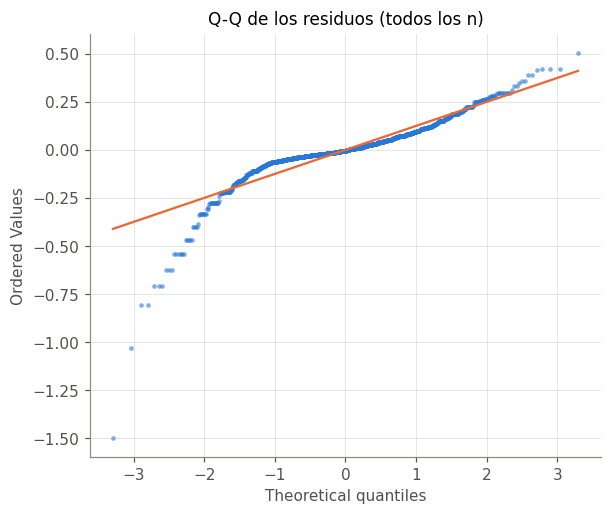

In [22]:
res_todos = r_todos["resid"]
W, p = stats.shapiro(res_todos)
print(f"Shapiro-Wilk, residuos de todos los n: W = {W:.4f}, p-valor = {p:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_todos, dist="norm", plot=ax)
puntos, recta = ax.get_lines()
puntos.set(color=AZUL, markersize=3, alpha=0.6, markeredgewidth=0)
recta.set(color=NARANJA, linewidth=1.5)
ax.set_title("Q-Q de los residuos (todos los n)")
plt.show()

Ahora el test con los residuos de cada $n$ por separado (calculados con el mismo ajuste de todos los $n$), junto con su media, desvío y asimetría.

In [23]:
b0_hat, b1_hat = r_todos["beta"]
filas = []
for m in ns:
    res_m = np.log(sn_tamanos[m]) - (b0_hat + b1_hat * np.log(m))
    W_m, p_m = stats.shapiro(res_m)
    filas.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05,
                  "media del residuo": res_m.mean(), "desvío del residuo": res_m.std(ddof=1),
                  "asimetría": stats.skew(res_m)})
tabla_41d = pd.DataFrame(filas).set_index("n")
tabla_41d.round(4)

,W,p-valor,¿rechaza al 5 %?,media del residuo,desvío del residuo,asimetría
n,,,,,,
10,0.9346,0.0000,True,-0.0657,0.2844,-1.1914
20,0.9895,0.1524,False,0.0298,0.1598,-0.1408
50,0.9940,0.5985,False,0.0391,0.0977,0.0910
100,0.9899,0.1718,False,0.0258,0.0690,-0.3266
200,0.9914,0.2807,False,0.0102,0.0471,-0.1898
500,0.9963,0.9128,False,-0.0102,0.0309,-0.0953
1000,0.9950,0.7485,False,-0.0290,0.0211,-0.0614


Con los residuos de todos los $n$ juntos, Shapiro–Wilk da $W = 0{,}824$ y $p = 1{,}1\cdot 10^{-36}$: rechaza con claridad. El Q-Q muestra por qué: el centro es muy plano (la mayoría de los residuos son de $n$ grande y tienen desvíos de $0{,}02$ a $0{,}07$) y las colas son largas, sobre todo la izquierda, que llega a $-1{,}5$.

Por separado, el test solo rechaza con $n = 10$ ($W = 0{,}935$, $p \approx 0$, asimetría $-1{,}19$). Para $n = 20, \dots, 1000$ los $p$-valores van de $0{,}15$ a $0{,}91$ y no rechaza. Dentro de cada $n$ la normalidad es razonable porque $S_n$ es aproximadamente normal y, con desvío relativo chico, $\ln$ es casi una transformación lineal. Con $n = 10$ el desvío relativo es $0{,}25$ ($S_{10}$ es un entero entre $0$ y $45$), y el logaritmo estira la cola izquierda, que es la de los valores chicos.

**Qué explica la diferencia.** El supuesto del modelo es que los errores son $N(0, \sigma^2)$ con el mismo $\sigma$ para todos los $n$. Los residuos juntos son una mezcla de $7$ grupos con escalas muy distintas (el ítem c)) y con medias distintas de cero: la media del residuo va de $-0{,}066$ ($n = 10$) a $+0{,}039$ ($n = 50$), porque la recta no ajusta exactamente la media de cada $n$ (la relación entre $\mathrm{E}[\ln S_n]$ y $\ln n$ está curvada, como vimos en b)). A $n$ grande esos corrimientos son tan grandes como el desvío mismo ($-0{,}029$ contra $0{,}021$ con $n = 1000$). Una mezcla de normales con distintos parámetros no es normal: tiene colas pesadas, y Shapiro–Wilk con $1400$ datos lo detecta.

Para verificarlo, en la siguiente tabla se van quitando esas diferencias entre grupos y se vuelve a testear con todos los residuos juntos.

In [24]:
# ¿De dónde viene el rechazo con todos los n juntos? Se van quitando de a una las diferencias entre grupos
res_por_n = {m: np.log(sn_tamanos[m]) - (b0_hat + b1_hat * np.log(m)) for m in ns}

def centrar(r): return r - r.mean()
def escalar(r): return r / r.std(ddof=1)
def ambos(r): return escalar(centrar(r))

def pooled_p(transformacion, excluir=()):
    juntos = np.concatenate([transformacion(r) for m, r in res_por_n.items() if m not in excluir])
    return stats.shapiro(juntos)[1]

pd.DataFrame({
    "residuos tal cual": [pooled_p(lambda r: r), pooled_p(lambda r: r, excluir=(10,))],
    "misma media en cada n": [pooled_p(centrar), pooled_p(centrar, excluir=(10,))],
    "mismo desvío en cada n": [pooled_p(escalar), pooled_p(escalar, excluir=(10,))],
    "misma media y mismo desvío": [pooled_p(ambos), pooled_p(ambos, excluir=(10,))],
}, index=["con n = 10", "sin n = 10"]).map("{:.1e}".format)

,residuos tal cual,misma media en cada n,mismo desvío en cada n,misma media y mismo desvío
con n = 10,1.1e-36,1.1e-35,4.9e-06,1.7e-04
sin n = 10,2.0e-20,1.8e-22,3.1e-04,4.4e-01


Igualar solo las medias no alcanza $(p = 10⁻³⁵)$; igualar solo los desvíos ayuda pero sigue rechazando $(p = 5·10⁻⁶)$; recién igualando media y desvío y sacando $n = 10$ el p-valor es $0,44$.

**Conclusión.** La normalidad se cumple aproximadamente dentro de cada $n \geq 20$, y el rechazo con todos los $n$ juntos viene de la misma fuente que en c): la varianza no es constante (más el desajuste de las medias y el caso $n = 10$). Como cada grupo tiene $200$ observaciones y los estimadores son combinaciones lineales, los intervalos y tests siguen siendo aproximadamente válidos por el teorema central del límite, siempre que se usen errores estándar robustos.